# 🧠🎙️ Multimodal Parkinson's Disease Detection — Drawing + Voice Fusion

**Authors:** Md. Abu Sayem

| Modality | Dataset | Features |
|---|---|---|
| ✍️ Drawing | PD-Dataset (Spiral + Wave, 204 images) | MobileNetV2 (1280-D, frozen) + HOG + LBP → StandardScaler → PCA(95%) |
| 🎙️ Voice | UCI Parkinson's (Little et al., 2007) — 195 recordings, ≈31 subjects | 22 dysphonia features (Jitter, Shimmer, HNR, RPDE, DFA, PPE …) |

**Pipeline:** Class-balanced unimodal baselines (voice: repeated subject-wise CV) → out-of-fold Platt calibration →
**6 fusion strategies** over 30 repetitions (Weighted Late, Product Rule, Meta-Learner, Early Fusion SVM/XGB, and the proposed
**Adaptive Confidence-Weighted Fusion — ACWF**) → robustness (noise + missing modality) → statistics → deployment artifacts.



## ⚠️ Methodological note

Drawing আর Voice dataset **ভিন্ন ভিন্ন মানুষের** কাছ থেকে নেওয়া — একই রোগীর drawing + voice কোনো public dataset-এ একসাথে নেই।
তাই এই notebook-এ:

1. **Voice split subject-wise** (একই মানুষের recording train আর test দুই জায়গায় যাবে না) → data leakage নেই। অনেক paper এই ভুলটা করে 95–100% accuracy দেখায়।
2. **Class-matched pseudo-pairing:** প্রতিটি drawing sample-এর সাথে *একই class-এর* একটা voice sample random-ভাবে জোড়া লাগানো হয় (train↔train, test↔test আলাদা)। প্রতিবার **নতুন voice-subject split + নতুন pairing** দিয়ে মোট **R = 30 বার** চালিয়ে **mean ± std** report করা হয়।
   (একটা মাত্র voice test split-এ মাত্র ~৬ জন মানুষ থাকে, তাই একবারের result খুব অস্থির — repetition দিয়ে এই সমস্যা দূর হয়।)
3. এটাকে paper-এ **"simulated multimodal cohort"**, এবং future work-এ real paired data (যেমন mPower বা নিজস্ব data collection)

In [1]:
# ============================================================
# STEP 1 — Install & Import
# ============================================================
!pip install -q xgboost scikit-image ucimlrepo

import os, glob, json, zipfile, shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from skimage.feature import hog, local_binary_pattern
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, roc_curve)
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from scipy import stats
import joblib

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

# ---------------- Config ----------------
BASE_DIR   = os.environ.get('PD_BASE', '/content')
DATA_DIR   = os.path.join(BASE_DIR, 'PD_data')
OUT_DIR    = os.path.join(BASE_DIR, 'multimodal_outputs')
FIG_DIR    = os.path.join(OUT_DIR, 'figures')
MODEL_DIR  = os.path.join(OUT_DIR, 'models')
for d in [DATA_DIR, OUT_DIR, FIG_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

DRAW_FEATURE_SET = 'hybrid'   # 'hybrid' = CNN + HOG + LBP  |  'cnn' = MobileNetV2 only (same as deployed M2)
N_PAIRINGS       = 30         # number of random pseudo-pairings (mean ± std)
CLASS_NAMES      = ['Healthy', 'Parkinson']

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches='tight')

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('✅ Libraries ready | Colab:', IN_COLAB, '| Output dir:', OUT_DIR)

✅ Libraries ready | Colab: True | Output dir: /content/multimodal_outputs


In [2]:
# ============================================================
# STEP 2 — Load UCI Parkinson's Voice Dataset (auto download)
# ============================================================
VOICE_URL   = 'https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data'
VOICE_MIRROR = 'https://raw.githubusercontent.com/cuuupid/parkinsons-ai/276b2216d879155d6172e071eca1fb0984693116/parkinsons.data'
LOCAL_VOICE = os.path.join(BASE_DIR, 'parkinsons.data')

def load_voice():
    if os.path.exists(LOCAL_VOICE):
        print('📂 Using local file:', LOCAL_VOICE)
        return pd.read_csv(LOCAL_VOICE)
    try:
        df = pd.read_csv(VOICE_URL)
        df.to_csv(LOCAL_VOICE, index=False)
        print('🌐 Downloaded from UCI archive')
        return df
    except Exception as e:
        print('UCI direct download failed:', e)
    try:   # public GitHub mirror of the same UCI file
        df = pd.read_csv(VOICE_MIRROR)
        df.to_csv(LOCAL_VOICE, index=False)
        print('🌐 Downloaded from GitHub mirror')
        return df
    except Exception as e:
        print('GitHub mirror failed:', e)
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=174)
        df = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1)
        print('🌐 Loaded via ucimlrepo')
        return df
    except Exception as e:
        print('ucimlrepo failed:', e)
    if IN_COLAB:
        print('⬆️ Please upload parkinsons.data manually')
        up = colab_files.upload()
        return pd.read_csv(list(up.keys())[0])
    raise RuntimeError('Voice dataset not found')

voice_df = load_voice()
voice_df['subject'] = voice_df['name'].astype(str).str.rsplit('_', n=1).str[0]
VOICE_FEATURES = [c for c in voice_df.columns if c not in ('name', 'status', 'subject')]

Xv_all = voice_df[VOICE_FEATURES].values.astype(np.float32)
yv_all = voice_df['status'].values.astype(int)          # 1 = PD, 0 = Healthy
gv_all = voice_df['subject'].values

subj = voice_df.groupby('subject')['status'].first()
print(f'Recordings : {len(voice_df)}  (PD={yv_all.sum()}, Healthy={(yv_all==0).sum()})')
print(f'Subject IDs: {subj.size}  (PD={int(subj.sum())}, Healthy={int((subj==0).sum())})')
print(f'Features   : {len(VOICE_FEATURES)}')
voice_df.head()

🌐 Downloaded from UCI archive
Recordings : 195  (PD=147, Healthy=48)
Subject IDs: 32  (PD=24, Healthy=8)
Features   : 22


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE,subject
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654,phon_R01_S01
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674,phon_R01_S01
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634,phon_R01_S01
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975,phon_R01_S01
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335,phon_R01_S01


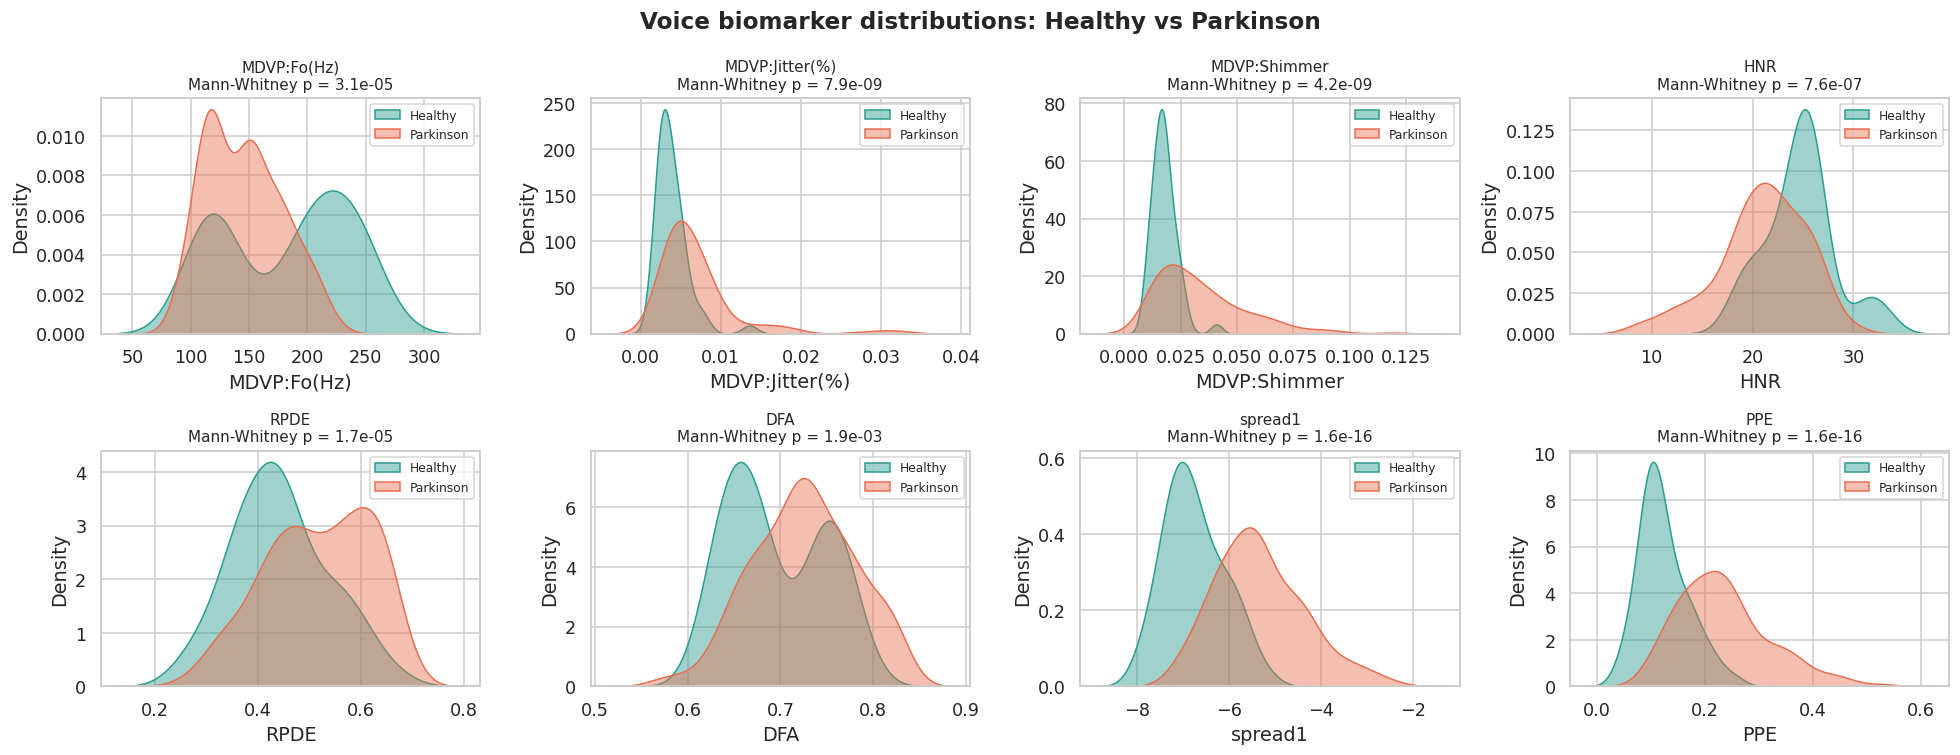

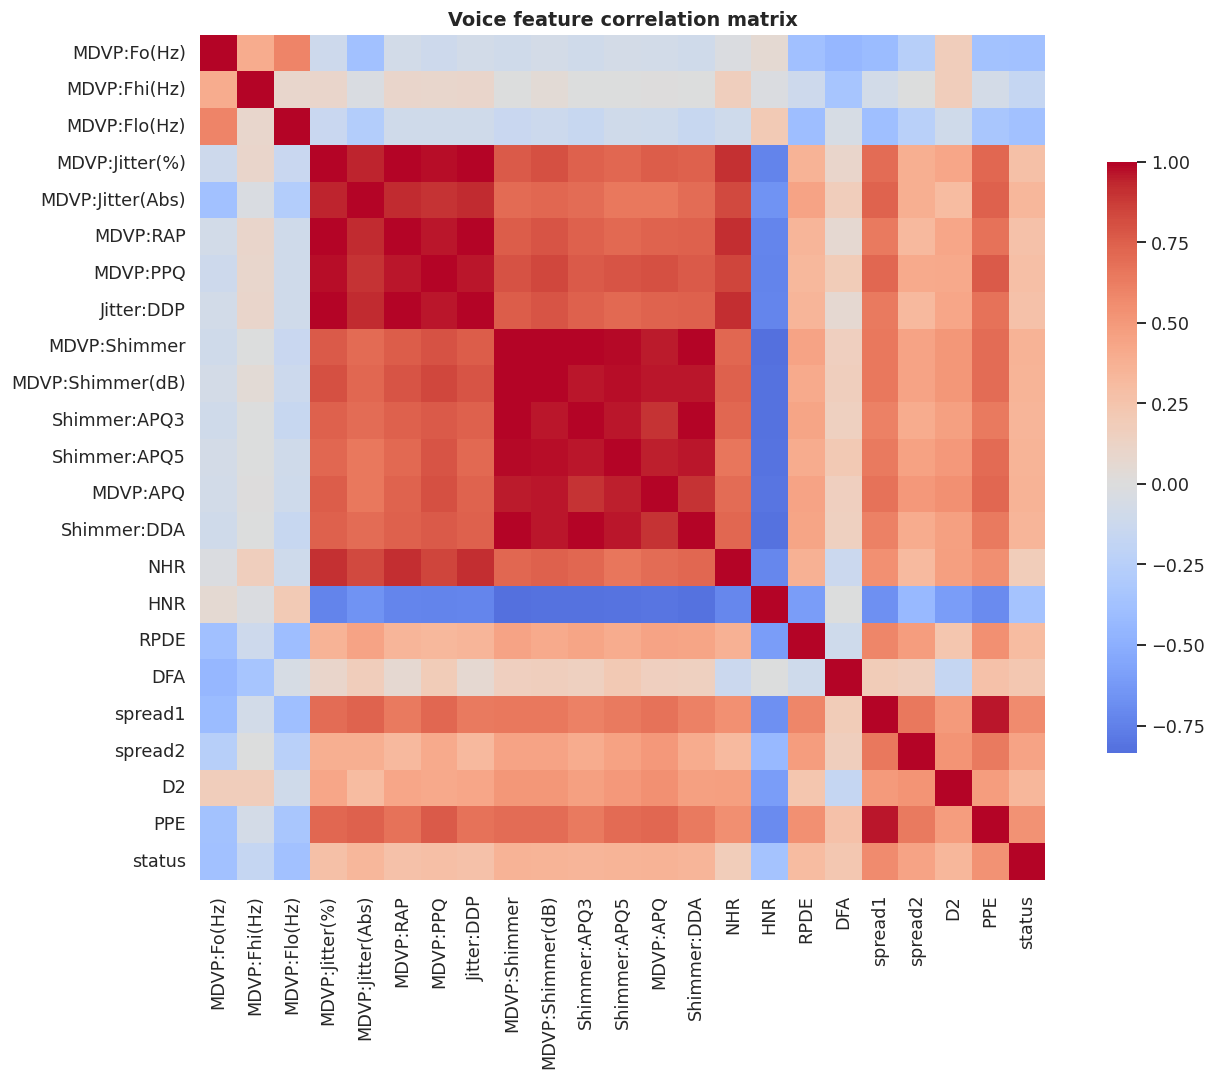

In [3]:
# ============================================================
# STEP 3 — Voice EDA (distribution + correlation)
# ============================================================
key_feats = ['MDVP:Fo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Shimmer', 'HNR', 'RPDE', 'DFA', 'spread1', 'PPE']
key_feats = [f for f in key_feats if f in VOICE_FEATURES]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.ravel(), key_feats):
    for lbl, col in [(0, '#2a9d8f'), (1, '#e76f51')]:
        sns.kdeplot(voice_df.loc[voice_df.status == lbl, f], ax=ax, fill=True, alpha=.45,
                    color=col, label=CLASS_NAMES[lbl])
    t, p = stats.mannwhitneyu(voice_df.loc[voice_df.status == 0, f], voice_df.loc[voice_df.status == 1, f])
    ax.set_title(f'{f}\nMann-Whitney p = {p:.1e}', fontsize=10)
    ax.legend(fontsize=8)
plt.suptitle('Voice biomarker distributions: Healthy vs Parkinson', fontweight='bold')
plt.tight_layout(); savefig('fig01_voice_distributions.png'); plt.show()

plt.figure(figsize=(13, 10))
sns.heatmap(voice_df[VOICE_FEATURES + ['status']].corr(), cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': .7})
plt.title('Voice feature correlation matrix', fontweight='bold')
plt.tight_layout(); savefig('fig02_voice_correlation.png'); plt.show()

In [4]:
# ============================================================
# STEP 4 — Drawing dataset (auto download from GitHub — no upload needed)
# ============================================================
# Spiral/Wave drawings (Zham et al., 2017; same 204 images as the Kaggle
# "parkinsons-drawings" set) mirrored in a public GitHub repo.
# Only the image folders are downloaded (sparse checkout, ~few MB).
import subprocess
DRAW_REPO = 'https://github.com/gina-santana/Parkinsons_image_classification.git'
REPO_DIR  = os.path.join(DATA_DIR, 'github_drawings')

def download_drawings():
    if glob.glob(os.path.join(REPO_DIR, 'data', '**', '*.png'), recursive=True):
        print('📂 Drawings already downloaded'); return True
    try:
        shutil.rmtree(REPO_DIR, ignore_errors=True)
        subprocess.run(['git', 'clone', '-q', '--depth', '1', '--filter=blob:none', '--sparse', DRAW_REPO, REPO_DIR], check=True)
        subprocess.run(['git', '-C', REPO_DIR, 'sparse-checkout', 'set', 'data/spiral', 'data/wave'], check=True)
        print('🌐 Drawings downloaded from GitHub')
        return True
    except Exception as e:
        print('GitHub download failed:', e); return False

if not download_drawings():
    # Fallback: local / uploaded PD-Dataset.zip
    ZIP_PATH = os.path.join(BASE_DIR, 'PD-Dataset.zip')
    if not os.path.exists(ZIP_PATH) and IN_COLAB:
        print('⬆️ Upload PD-Dataset.zip')
        up = colab_files.upload()
        ZIP_PATH = os.path.join(BASE_DIR, list(up.keys())[0])
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')
records, seen = [], set()
for path in sorted(glob.glob(os.path.join(DATA_DIR, '**', '*'), recursive=True)):
    if not path.lower().endswith(IMG_EXT):
        continue
    parts = path.replace('\\', '/').lower().split('/')
    shape = 'spiral' if 'spiral' in parts else 'wave' if 'wave' in parts else None
    split = 'train' if 'training' in parts else 'test' if 'testing' in parts else None
    label = 1 if 'parkinson' in parts else 0 if 'healthy' in parts else None
    if None in (shape, split, label):
        continue
    key = (shape, split, label, os.path.basename(path))   # removes the duplicate 'drawings/' copy
    if key in seen:
        continue
    seen.add(key)
    records.append(dict(path=path, shape=shape, split=split, label=label))

draw_df = pd.DataFrame(records)
print(draw_df.groupby(['split', 'shape', 'label']).size().unstack(fill_value=0).rename(columns={0: 'Healthy', 1: 'Parkinson'}))
print('Total unique images:', len(draw_df))

🌐 Drawings downloaded from GitHub
label         Healthy  Parkinson
split shape                     
test  spiral       15         15
      wave         15         15
train spiral       36         36
      wave         36         36
Total unique images: 204


In [5]:
# ============================================================
# STEP 5 — Drawing feature extraction (MobileNetV2 + HOG + LBP)
# ============================================================
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Input
from tensorflow.keras.models import Model
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

def build_cnn_extractor():
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False
    inp = Input(shape=(224, 224, 3))
    out = GlobalAveragePooling2D()(base(inp, training=False))
    return Model(inp, out, name='mobilenetv2_gap_extractor')

def cnn_features(paths, extractor, batch=32):
    feats = []
    for i in range(0, len(paths), batch):
        imgs = [np.array(Image.open(p).convert('RGB').resize((224, 224), Image.LANCZOS), dtype=np.float32)
                for p in paths[i:i + batch]]
        feats.append(extractor.predict(preprocess_input(np.stack(imgs)), verbose=0))
    return np.vstack(feats)

def handcrafted_features(path):
    g = np.array(Image.open(path).convert('L').resize((128, 128), Image.LANCZOS), dtype=np.float32) / 255.
    h = hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')
    lbp = local_binary_pattern((g * 255).astype(np.uint8), P=24, R=3, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=26, range=(0, 26), density=True)
    return np.concatenate([h, lbp_hist])

t0 = time.time()
cnn_extractor = build_cnn_extractor()
F_cnn = cnn_features(draw_df.path.tolist(), cnn_extractor)
if DRAW_FEATURE_SET == 'hybrid':
    F_hc = np.vstack([handcrafted_features(p) for p in draw_df.path])
    F_draw = np.hstack([F_cnn, F_hc]).astype(np.float32)
else:
    F_draw = F_cnn.astype(np.float32)
print(f'✅ Drawing features: {F_draw.shape}  ({time.time() - t0:.1f}s)  set = {DRAW_FEATURE_SET}')

tr_mask = (draw_df.split == 'train').values
Xd_tr, Xd_te = F_draw[tr_mask], F_draw[~tr_mask]
yd_tr, yd_te = draw_df.label.values[tr_mask], draw_df.label.values[~tr_mask]
print(f'Drawing train: {Xd_tr.shape}  test: {Xd_te.shape}')

TensorFlow 2.21.0 | GPU: False
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Drawing features: (204, 9406)  (40.8s)  set = hybrid
Drawing train: (144, 9406)  test: (60, 9406)


In [6]:
# ============================================================
# STEP 6 — Class-balanced model zoo, pipelines, metrics, calibration
# ============================================================
SPW_VOICE = float((yv_all == 0).sum() / (yv_all == 1).sum())   # XGBoost weight for the 75 % PD imbalance

def model_zoo(scale_pos_weight=1.0):
    svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True, class_weight='balanced', random_state=SEED)
    rf  = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1)
    xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                        scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=SEED, n_jobs=-1)
    lr  = LogisticRegression(C=1.0, max_iter=5000, class_weight='balanced', random_state=SEED)
    knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
    return {
        'SVM (RBF)':     svm,
        'Random Forest': rf,
        'XGBoost':       xgb,
        'Logistic Reg.': lr,
        'KNN':           knn,
        'Soft Voting':   VotingClassifier([('svm', clone(svm)), ('rf', clone(rf)), ('xgb', clone(xgb)), ('lr', clone(lr))], voting='soft'),
        'Stacking':      StackingClassifier([('svm', clone(svm)), ('rf', clone(rf)), ('xgb', clone(xgb))],
                                            final_estimator=LogisticRegression(max_iter=5000, class_weight='balanced'), cv=5),
    }

def make_pipeline(modality, clf):
    if modality == 'drawing':
        return Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=0.95, random_state=SEED)), ('clf', clf)])
    return Pipeline([('scaler', StandardScaler()), ('clf', clf)])

def metrics(y, prob, thr=0.5):
    pred = (np.asarray(prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred),
                BalAcc=balanced_accuracy_score(y, pred),
                Precision=precision_score(y, pred, zero_division=0),
                Sensitivity=recall_score(y, pred, zero_division=0),
                Specificity=tn / (tn + fp) if (tn + fp) else 0.0,
                F1=f1_score(y, pred, zero_division=0),
                AUC=roc_auc_score(y, prob) if len(np.unique(y)) == 2 else np.nan,
                MCC=matthews_corrcoef(y, pred))

def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps); return np.log(p / (1 - p))

class PlattCalibrator:
    # Maps raw scores to calibrated, prevalence-balanced probabilities (fitted on out-of-fold scores only)
    def fit(self, p, y):
        self.lr = LogisticRegression(C=100, class_weight='balanced', max_iter=1000).fit(logit(p)[:, None], y); return self
    def transform(self, p):
        return self.lr.predict_proba(logit(p)[:, None])[:, 1]

def oof_proba(modality, clf, X, y, groups=None, seed=SEED, n_splits=5):
    if groups is None:
        splits = StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y)
    else:
        splits = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(X, y, groups)
    o = np.zeros(len(y))
    for a, b in splits:
        o[b] = make_pipeline(modality, clone(clf)).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    return o

MET = ['Accuracy', 'BalAcc', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'AUC', 'MCC']
print(f'✅ 7 class-balanced classifiers ready | voice XGB scale_pos_weight = {SPW_VOICE:.3f}')

✅ 7 class-balanced classifiers ready | voice XGB scale_pos_weight = 0.327


In [7]:
# ============================================================
# STEP 7 — DRAWING unimodal (official train/test split)
# ============================================================
# Model selection uses TRAIN 5-fold CV AUC only (no test-set peeking).
cv_d = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xd_tr, yd_tr))
rows, oof_d, prob_d, fit_d = [], {}, {}, {}
for name, clf in model_zoo().items():
    t0 = time.time()
    o = np.zeros(len(yd_tr))
    for a, b in cv_d:
        o[b] = make_pipeline('drawing', clone(clf)).fit(Xd_tr[a], yd_tr[a]).predict_proba(Xd_tr[b])[:, 1]
    pipe = make_pipeline('drawing', clone(clf)).fit(Xd_tr, yd_tr)
    p = pipe.predict_proba(Xd_te)[:, 1]
    oof_d[name], prob_d[name], fit_d[name] = o, p, pipe
    m = metrics(yd_te, p)
    rows.append(dict(Modality='Drawing', Model=name, Protocol='official split (144 train / 60 test)',
                     Select_AUC=roc_auc_score(yd_tr, o), **m, **{f'{k}_std': 0.0 for k in m}, Time_s=time.time() - t0))
    print(f'  drawing | {name:14s} | train-CV AUC {rows[-1]["Select_AUC"]:.3f} | test Acc {m["Accuracy"]:.3f}  AUC {m["AUC"]:.3f}')
res_d = pd.DataFrame(rows)
BEST_D = res_d.sort_values(['Select_AUC'], ascending=False).Model.iloc[0]
cal_d = PlattCalibrator().fit(oof_d[BEST_D], yd_tr)
REL_D = max(roc_auc_score(yd_tr, oof_d[BEST_D]) - 0.5, 0.01)       # reliability used by ACWF
print(f'\n🏆 Best drawing model (by train CV): {BEST_D}')

  drawing | SVM (RBF)      | train-CV AUC 0.921 | test Acc 0.767  AUC 0.899
  drawing | Random Forest  | train-CV AUC 0.857 | test Acc 0.733  AUC 0.868
  drawing | XGBoost        | train-CV AUC 0.821 | test Acc 0.800  AUC 0.870
  drawing | Logistic Reg.  | train-CV AUC 0.887 | test Acc 0.800  AUC 0.902
  drawing | KNN            | train-CV AUC 0.839 | test Acc 0.600  AUC 0.823
  drawing | Soft Voting    | train-CV AUC 0.889 | test Acc 0.817  AUC 0.903
  drawing | Stacking       | train-CV AUC 0.885 | test Acc 0.783  AUC 0.902

🏆 Best drawing model (by train CV): SVM (RBF)


In [8]:
# ============================================================
# STEP 8 — VOICE unimodal: repeated SUBJECT-WISE 5-fold CV (all 195 recordings)
# ============================================================
# A single held-out fold contains only ~6 subjects, so its accuracy swings wildly
# with the split seed. Repeated subject-wise CV gives a stable, leakage-free estimate.
N_VOICE_REPEATS = 5
rows, voice_oof = [], {}
for name, clf in model_zoo(SPW_VOICE).items():
    t0, reps, subj = time.time(), [], []
    for k in range(N_VOICE_REPEATS):
        o = oof_proba('voice', clf, Xv_all, yv_all, gv_all, seed=SEED + k)
        voice_oof.setdefault(name, []).append(o)
        reps.append(metrics(yv_all, o))
        sp = pd.DataFrame({'g': gv_all, 'p': o, 'y': yv_all}).groupby('g').mean()
        subj.append(balanced_accuracy_score(sp.y.astype(int), (sp.p >= .5).astype(int)))
    R = pd.DataFrame(reps)
    rows.append(dict(Modality='Voice', Model=name, Protocol=f'subject-wise 5-fold CV × {N_VOICE_REPEATS}',
                     Select_AUC=R.AUC.mean(), **R.mean().to_dict(), **{f'{c}_std': R[c].std() for c in R},
                     Subject_BalAcc=np.mean(subj), Time_s=time.time() - t0))
    print(f'  voice   | {name:14s} | AUC {R.AUC.mean():.3f} ± {R.AUC.std():.3f} | BalAcc {R.BalAcc.mean():.3f} | subject-level BalAcc {np.mean(subj):.3f}')
res_v = pd.DataFrame(rows)
BEST_V = res_v.sort_values(['Select_AUC', 'BalAcc'], ascending=False).Model.iloc[0]
print(f'\n🏆 Best voice model (by subject-wise CV AUC): {BEST_V}')

unimodal = pd.concat([res_d, res_v], ignore_index=True)
unimodal.to_csv(os.path.join(OUT_DIR, 'unimodal_all_models.csv'), index=False)
display(unimodal[['Modality', 'Model', 'Protocol', 'Accuracy', 'BalAcc', 'Sensitivity', 'Specificity', 'F1', 'AUC', 'MCC']].round(4))

  voice   | SVM (RBF)      | AUC 0.675 ± 0.039 | BalAcc 0.601 | subject-level BalAcc 0.613
  voice   | Random Forest  | AUC 0.755 ± 0.012 | BalAcc 0.606 | subject-level BalAcc 0.629
  voice   | XGBoost        | AUC 0.802 ± 0.041 | BalAcc 0.673 | subject-level BalAcc 0.696
  voice   | Logistic Reg.  | AUC 0.766 ± 0.015 | BalAcc 0.654 | subject-level BalAcc 0.683
  voice   | KNN            | AUC 0.740 ± 0.036 | BalAcc 0.610 | subject-level BalAcc 0.637
  voice   | Soft Voting    | AUC 0.771 ± 0.016 | BalAcc 0.641 | subject-level BalAcc 0.683
  voice   | Stacking       | AUC 0.691 ± 0.037 | BalAcc 0.648 | subject-level BalAcc 0.675

🏆 Best voice model (by subject-wise CV AUC): XGBoost


,Modality,Model,Protocol,Accuracy,BalAcc,Sensitivity,Specificity,F1,AUC,MCC
0,Drawing,SVM (RBF),official split (144 train / 60 test),0.7667,0.7667,0.5667,0.9667,0.7083,0.8989,0.5819
1,Drawing,Random Forest,official split (144 train / 60 test),0.7333,0.7333,0.5333,0.9333,0.6667,0.8683,0.5092
2,Drawing,XGBoost,official split (144 train / 60 test),0.8000,0.8000,0.6667,0.9333,0.7692,0.8700,0.6225
3,Drawing,Logistic Reg.,official split (144 train / 60 test),0.8000,0.8000,0.8333,0.7667,0.8065,0.9022,0.6013
4,Drawing,KNN,official split (144 train / 60 test),0.6000,0.6000,0.3000,0.9000,0.4286,0.8233,0.2500
5,Drawing,Soft Voting,official split (144 train / 60 test),0.8167,0.8167,0.7000,0.9333,0.7925,0.9033,0.6513
6,Drawing,Stacking,official split (144 train / 60 test),0.7833,0.7833,0.6000,0.9667,0.7347,0.9022,0.6091
7,Voice,SVM (RBF),subject-wise 5-fold CV × 5,0.7641,0.6008,0.9224,0.2792,0.8551,0.6747,0.2564
8,Voice,Random Forest,subject-wise 5-fold CV × 5,0.7703,0.6063,0.9293,0.2833,0.8593,0.7550,0.2702
9,Voice,XGBoost,subject-wise 5-fold CV × 5,0.7826,0.6734,0.8884,0.4583,0.8603,0.8020,0.3764


In [9]:
# ============================================================
# STEP 9 — Multimodal fusion: 30 repetitions
#   each repetition = new subject-wise voice split + new class-matched pseudo-pairing
# ============================================================
VOICE_TEST_FRAC = 0.30
W_GRID     = np.round(np.arange(0, 1.0001, 0.05), 2)
GAMMA_GRID = [0.0, 0.5, 1.0, 2.0]
NOISE      = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0]
STRATS = ['Weighted Late Fusion', 'Product Rule', 'Meta-Learner (LR)',
          'Early Fusion (SVM)', 'Early Fusion (XGB)', 'ACWF (proposed)']
voice_subj = pd.Series(yv_all, index=gv_all).groupby(level=0).first()

def split_voice_subjects(r):
    rng = np.random.default_rng(1000 + r); test_subj = []
    for c in (0, 1):
        s = voice_subj.index[voice_subj.values == c].values
        test_subj += list(rng.choice(s, max(2, int(round(len(s) * VOICE_TEST_FRAC))), replace=False))
    te = np.isin(gv_all, test_subj)
    return np.where(~te)[0], np.where(te)[0]

def pseudo_pair(y_anchor, y_other, rng):
    # each drawing sample gets a random voice sample of the SAME class (same split only)
    idx = np.empty(len(y_anchor), dtype=int)
    for c in (0, 1):
        pool, pos = np.where(y_other == c)[0], np.where(y_anchor == c)[0]
        idx[pos] = rng.choice(pool, size=len(pos), replace=len(pool) < len(pos))
    return idx

def product_rule(a, b):
    m = a * b; return m / (m + (1 - a) * (1 - b) + 1e-12)

def acwf(pd_, pv_, rel_d, rel_v, gamma):
    # Adaptive Confidence-Weighted Fusion (proposed)
    #   1) each modality's score is Platt-calibrated on out-of-fold data
    #   2) per-sample weight = modality reliability (train OOF AUC − 0.5) × confidence^gamma,
    #      confidence = |2p − 1|
    #   3) fusion in logit space; gamma is learned on the training pairs
    cd = rel_d * np.abs(2 * pd_ - 1) ** gamma + 1e-9
    cv = rel_v * np.abs(2 * pv_ - 1) ** gamma + 1e-9
    z = (cd * logit(pd_) + cv * logit(pv_)) / (cd + cv)
    return 1 / (1 + np.exp(-z))

draw_tf = Pipeline(fit_d[BEST_D].steps[:-1])                   # fitted scaler + PCA
Zd_tr, Zd_te = draw_tf.transform(Xd_tr), draw_tf.transform(Xd_te)
a_tr, a_te = cal_d.transform(oof_d[BEST_D]), cal_d.transform(prob_d[BEST_D])

LOG_KEYS = ['Drawing only', 'Voice only (subject-wise test)', 'Voice only (paired rows)'] + STRATS
log, store, sweep, rob = {k: [] for k in LOG_KEYS}, [], [], []
t_start = time.time()
for r in range(N_PAIRINGS):
    vtr, vte = split_voice_subjects(r)
    assert not set(gv_all[vtr]) & set(gv_all[vte])
    clf_v  = model_zoo(SPW_VOICE)[BEST_V]
    o_v    = oof_proba('voice', clf_v, Xv_all[vtr], yv_all[vtr], gv_all[vtr], seed=SEED + r)
    pipe_v = make_pipeline('voice', clone(clf_v)).fit(Xv_all[vtr], yv_all[vtr])
    cal_v  = PlattCalibrator().fit(o_v, yv_all[vtr])
    rel_v  = max(roc_auc_score(yv_all[vtr], o_v) - 0.5, 0.01)
    pv_tr_all = cal_v.transform(o_v)
    pv_te_all = cal_v.transform(pipe_v.predict_proba(Xv_all[vte])[:, 1])

    rng = np.random.default_rng(SEED + r)
    jtr, jte = pseudo_pair(yd_tr, yv_all[vtr], rng), pseudo_pair(yd_te, yv_all[vte], rng)
    b_tr, b_te = pv_tr_all[jtr], pv_te_all[jte]

    # ---- fusion hyper-parameters learned on TRAIN pairs only ----
    sc = [(accuracy_score(yd_tr, (w * a_tr + (1 - w) * b_tr >= .5).astype(int)),
           roc_auc_score(yd_tr, w * a_tr + (1 - w) * b_tr), -abs(w - .5)) for w in W_GRID]
    w_best = float(W_GRID[max(range(len(W_GRID)), key=lambda i: sc[i])])
    gs = [(accuracy_score(yd_tr, (acwf(a_tr, b_tr, REL_D, rel_v, g) >= .5).astype(int)),
           roc_auc_score(yd_tr, acwf(a_tr, b_tr, REL_D, rel_v, g)), -g) for g in GAMMA_GRID]
    g_best = GAMMA_GRID[max(range(len(GAMMA_GRID)), key=lambda i: gs[i])]
    meta = LogisticRegression(max_iter=1000).fit(np.c_[logit(a_tr), logit(b_tr)], yd_tr)
    vsc = StandardScaler().fit(Xv_all[vtr])
    Etr = np.hstack([Zd_tr, vsc.transform(Xv_all[vtr])[jtr]])
    Ete = np.hstack([Zd_te, vsc.transform(Xv_all[vte])[jte]])
    ef_svm = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, probability=True, random_state=SEED))]).fit(Etr, yd_tr)
    ef_xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=.1, eval_metric='logloss',
                           random_state=SEED, n_jobs=-1).fit(Etr, yd_tr)

    probs = {'Drawing only': a_te, 'Voice only (paired rows)': b_te,
             'Weighted Late Fusion': w_best * a_te + (1 - w_best) * b_te,
             'Product Rule': product_rule(a_te, b_te),
             'Meta-Learner (LR)': meta.predict_proba(np.c_[logit(a_te), logit(b_te)])[:, 1],
             'Early Fusion (SVM)': ef_svm.predict_proba(Ete)[:, 1],
             'Early Fusion (XGB)': ef_xgb.predict_proba(Ete)[:, 1],
             'ACWF (proposed)': acwf(a_te, b_te, REL_D, rel_v, g_best)}
    for k, p in probs.items():
        log[k].append(metrics(yd_te, p))
    log['Voice only (subject-wise test)'].append(metrics(yv_all[vte], pv_te_all))
    store.append(dict(rep=r, w=w_best, gamma=g_best, rel_v=rel_v, probs=probs,
                      voice_test_y=yv_all[vte], voice_test_p=pv_te_all, vtr=vtr, vte=vte, jtr=jtr, jte=jte))
    sweep.append([accuracy_score(yd_te, (w * a_te + (1 - w) * b_te >= .5).astype(int)) for w in W_GRID])

    # ---- robustness: corrupted voice at test time ----
    sd, rn = Xv_all[vtr].std(0), np.random.default_rng(SEED + 100 + r)
    for sigma in NOISE:
        Xn = Xv_all[vte] + rn.normal(0, 1, (len(vte), Xv_all.shape[1])) * sd * sigma
        bn = cal_v.transform(pipe_v.predict_proba(Xn)[:, 1])[jte]
        for name, p in [('Voice only', bn),
                        ('Weighted Late Fusion', w_best * a_te + (1 - w_best) * bn),
                        ('Early Fusion (SVM)', ef_svm.predict_proba(np.hstack([Zd_te, vsc.transform(Xn)[jte]]))[:, 1]),
                        ('ACWF (proposed)', acwf(a_te, bn, REL_D, rel_v, g_best))]:
            rob.append(dict(rep=r, Noise_sigma=sigma, Method=name, Accuracy=accuracy_score(yd_te, (p >= .5).astype(int))))
    if r == 0:
        print(f'⏱️ one repetition ≈ {time.time() - t_start:.1f}s → total ≈ {(time.time() - t_start) * N_PAIRINGS / 60:.1f} min')
    if (r + 1) % 10 == 0:
        print(f'   {r + 1}/{N_PAIRINGS} done | ACWF acc so far {np.mean([m["Accuracy"] for m in log["ACWF (proposed)"]]):.3f}')

W_FINAL     = float(np.median([s['w'] for s in store]))
GAMMA_FINAL = float(pd.Series([s['gamma'] for s in store]).mode().iloc[0])
print(f'✅ Done in {(time.time() - t_start) / 60:.1f} min | median w_draw = {W_FINAL:.2f} | most frequent ACWF gamma = {GAMMA_FINAL}')

⏱️ one repetition ≈ 1.0s → total ≈ 0.5 min
   10/30 done | ACWF acc so far 0.828
   20/30 done | ACWF acc so far 0.828
   30/30 done | ACWF acc so far 0.831
✅ Done in 0.5 min | median w_draw = 0.55 | most frequent ACWF gamma = 0.0


In [10]:
# ============================================================
# STEP 10 — Final comparison table (mean ± std over 30 repetitions)
# ============================================================
LABEL = {'Drawing only': f'Drawing only — {BEST_D}',
         'Voice only (subject-wise test)': f'Voice only — {BEST_V} (unseen subjects)',
         'Voice only (paired rows)': f'Voice only — {BEST_V} (paired rows)'}
rows = []
for k in LOG_KEYS:
    D = pd.DataFrame(log[k])
    rows.append(dict(Approach=LABEL.get(k, k), Key=k, Type='Unimodal' if 'only' in k else 'Multimodal',
                     **{f'{m}_mean': D[m].mean() for m in MET}, **{f'{m}_std': D[m].std() for m in MET}))
final_df = pd.DataFrame(rows)
BEST_FUSION = final_df[final_df.Type == 'Multimodal'].sort_values(['Accuracy_mean', 'AUC_mean'], ascending=False).Key.iloc[0]

pretty = final_df[['Approach', 'Type']].copy()
for m in MET:
    pretty[m] = [f'{a:.3f} ± {b:.3f}' if m in ('AUC', 'MCC') else f'{a*100:.2f} ± {b*100:.2f}'
                 for a, b in zip(final_df[f'{m}_mean'], final_df[f'{m}_std'])]
final_df.to_csv(os.path.join(OUT_DIR, 'multimodal_results_raw.csv'), index=False)
pretty.to_csv(os.path.join(OUT_DIR, 'multimodal_results_table.csv'), index=False)
print('🏆 Best fusion strategy:', BEST_FUSION)
print('ℹ️ Note: with two modalities, Product Rule and a 0.5/0.5 average always give the same class decision (p_d + p_v > 1).')
display(pretty)

🏆 Best fusion strategy: Product Rule
ℹ️ Note: with two modalities, Product Rule and a 0.5/0.5 average always give the same class decision (p_d + p_v > 1).


,Approach,Type,Accuracy,BalAcc,Precision,Sensitivity,Specificity,F1,AUC,MCC
0,Drawing only — SVM (RBF),Unimodal,78.33 ± 0.00,78.33 ± 0.00,77.42 ± 0.00,80.00 ± 0.00,76.67 ± 0.00,78.69 ± 0.00,0.899 ± 0.000,0.567 ± 0.000
1,Voice only — XGBoost (unseen subjects),Unimodal,70.07 ± 10.34,67.35 ± 13.30,87.78 ± 7.90,72.20 ± 12.37,62.50 ± 25.69,78.58 ± 8.43,0.757 ± 0.148,0.306 ± 0.238
2,Voice only — XGBoost (paired rows),Unimodal,67.89 ± 12.43,67.89 ± 12.43,69.98 ± 17.17,72.89 ± 13.47,62.89 ± 25.53,69.76 ± 10.25,0.757 ± 0.152,0.370 ± 0.264
3,Weighted Late Fusion,Multimodal,82.11 ± 6.19,82.11 ± 6.19,81.35 ± 7.45,84.78 ± 4.52,79.44 ± 12.81,82.77 ± 4.67,0.911 ± 0.033,0.647 ± 0.114
4,Product Rule,Multimodal,84.67 ± 4.28,84.67 ± 4.28,84.38 ± 6.05,85.78 ± 4.79,83.56 ± 8.16,84.89 ± 3.88,0.927 ± 0.025,0.697 ± 0.082
5,Meta-Learner (LR),Multimodal,83.83 ± 4.51,83.83 ± 4.51,83.02 ± 6.04,85.89 ± 5.72,81.78 ± 8.87,84.20 ± 4.05,0.922 ± 0.029,0.681 ± 0.085
6,Early Fusion (SVM),Multimodal,79.89 ± 7.91,79.89 ± 7.91,96.64 ± 6.19,62.00 ± 14.64,97.78 ± 4.04,74.62 ± 11.38,0.919 ± 0.089,0.643 ± 0.139
7,Early Fusion (XGB),Multimodal,71.06 ± 15.69,71.06 ± 15.69,69.21 ± 16.18,85.56 ± 10.80,56.56 ± 27.92,75.57 ± 11.56,0.823 ± 0.135,0.434 ± 0.335
8,ACWF (proposed),Multimodal,83.06 ± 3.42,83.06 ± 3.42,82.27 ± 4.93,84.78 ± 4.35,81.33 ± 6.64,83.37 ± 3.16,0.920 ± 0.020,0.664 ± 0.067


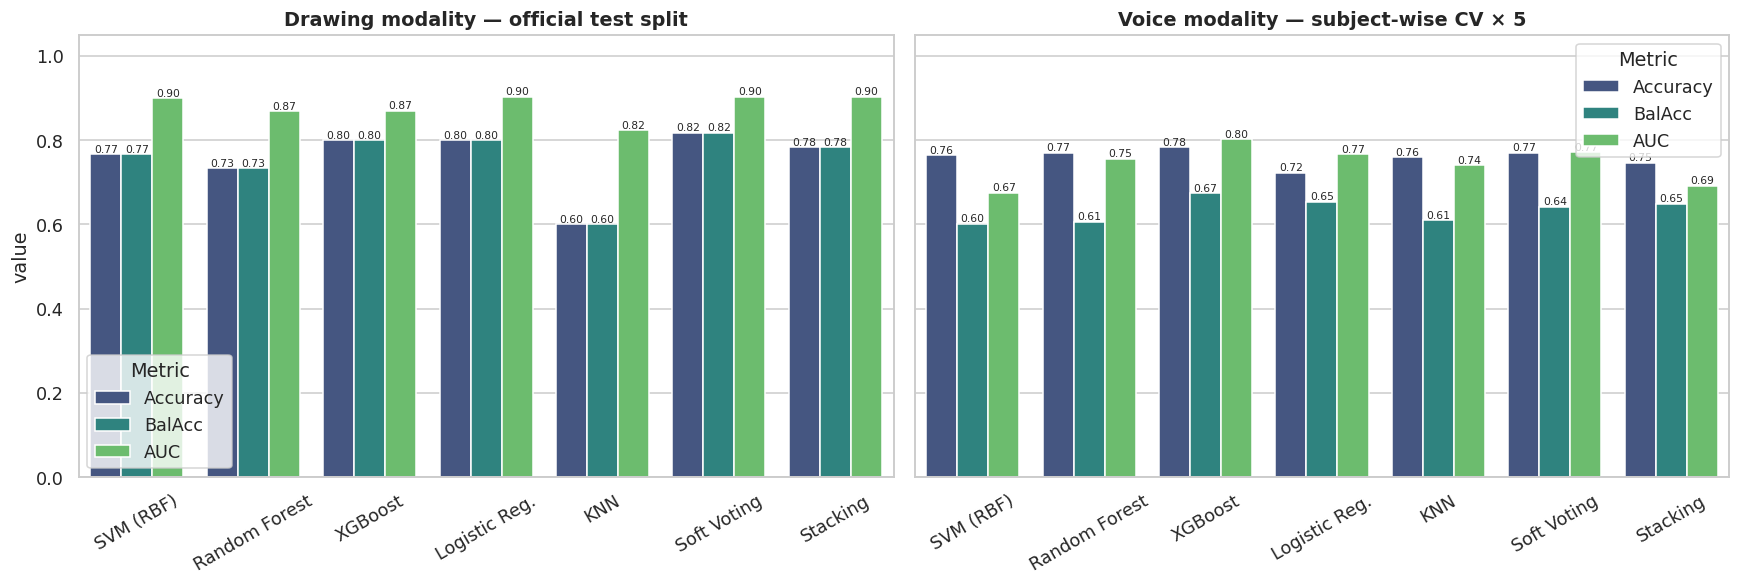

In [11]:
# ============================================================
# STEP 11 — Unimodal model comparison (all 7 classifiers)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, (mod, df_, sub) in zip(axes, [('Drawing', res_d, 'official test split'),
                                       ('Voice', res_v, f'subject-wise CV × {N_VOICE_REPEATS}')]):
    d = df_.melt(id_vars='Model', value_vars=['Accuracy', 'BalAcc', 'AUC'], var_name='Metric')
    sns.barplot(data=d, x='Model', y='value', hue='Metric', ax=ax, palette='viridis')
    ax.set_title(f'{mod} modality — {sub}', fontweight='bold')
    ax.set_ylim(0, 1.05); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout(); savefig('fig03_unimodal_comparison.png'); plt.show()

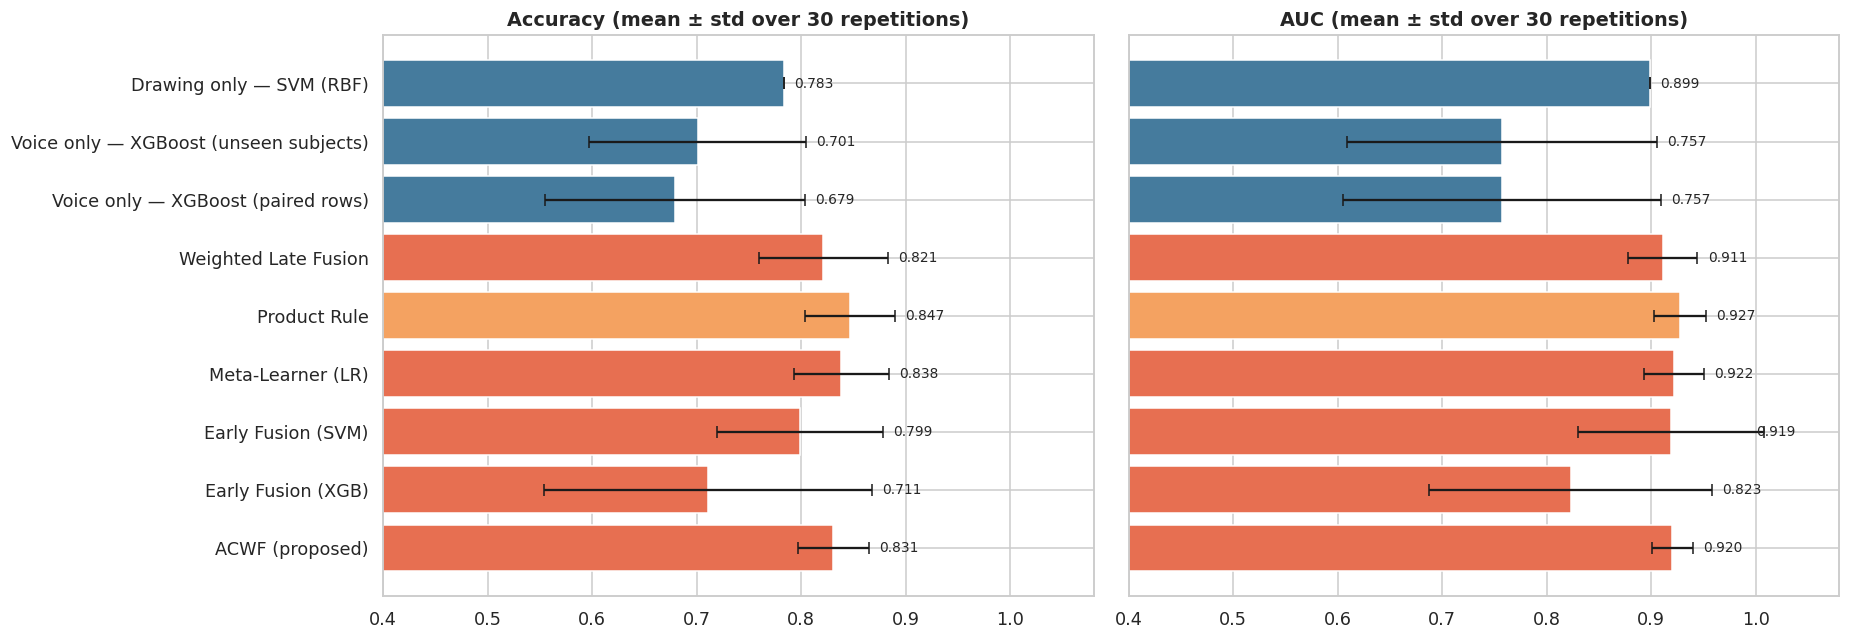

In [12]:
# ============================================================
# STEP 12 — Unimodal vs Multimodal (mean ± std)
# ============================================================
colors = ['#f4a261' if k == BEST_FUSION else '#457b9d' if t == 'Unimodal' else '#e76f51'
          for k, t in zip(final_df.Key, final_df.Type)]
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, m in zip(axes, ['Accuracy', 'AUC']):
    ax.barh(final_df.Approach, final_df[f'{m}_mean'], xerr=final_df[f'{m}_std'], color=colors, capsize=4)
    for i, (v, e) in enumerate(zip(final_df[f'{m}_mean'], final_df[f'{m}_std'])):
        ax.text(min(v + e + .01, 1.0), i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0.4, 1.08); ax.invert_yaxis()
    ax.set_title(f'{m} (mean ± std over {N_PAIRINGS} repetitions)', fontweight='bold')
axes[1].set_yticklabels([])
plt.tight_layout(); savefig('fig04_unimodal_vs_multimodal.png'); plt.show()

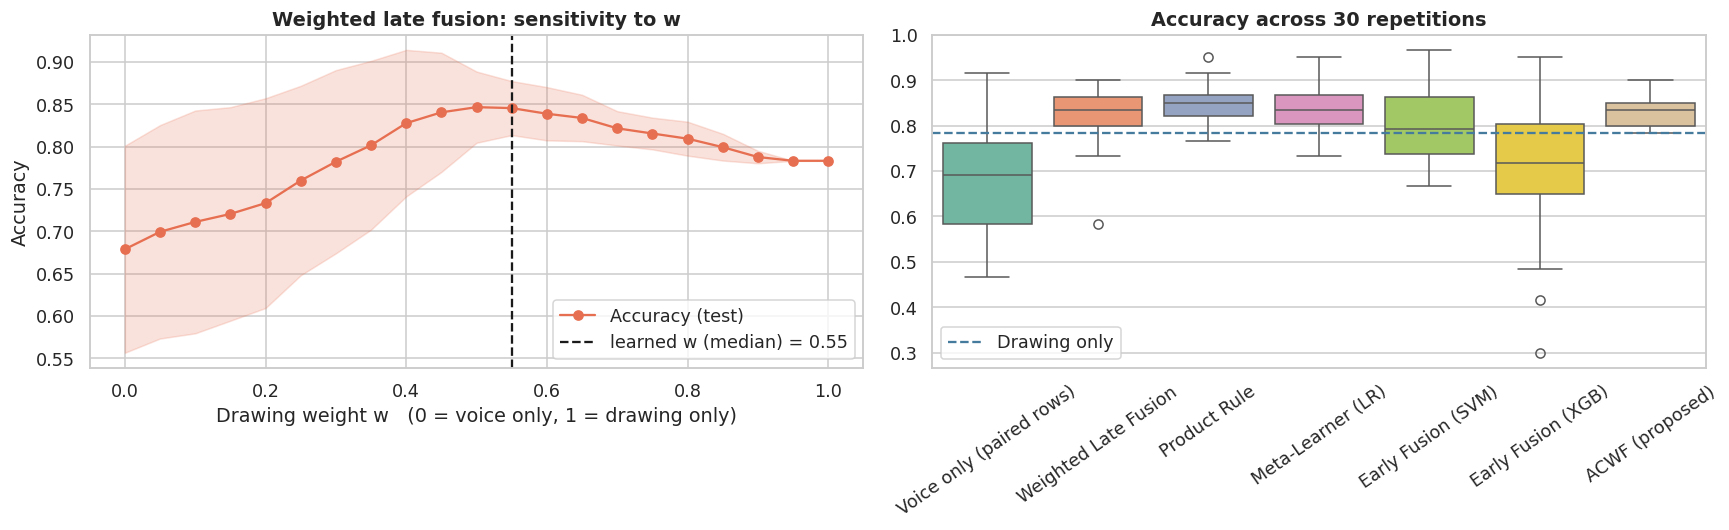

In [13]:
# ============================================================
# STEP 13 — Fusion-weight sensitivity + stability across repetitions
# ============================================================
sw = np.array(sweep)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.plot(W_GRID, sw.mean(0), 'o-', color='#e76f51', label='Accuracy (test)')
ax.fill_between(W_GRID, sw.mean(0) - sw.std(0), sw.mean(0) + sw.std(0), color='#e76f51', alpha=.2)
ax.axvline(W_FINAL, ls='--', color='k', label=f'learned w (median) = {W_FINAL:.2f}')
ax.set_xlabel('Drawing weight w   (0 = voice only, 1 = drawing only)'); ax.set_ylabel('Accuracy')
ax.set_title('Weighted late fusion: sensitivity to w', fontweight='bold'); ax.legend()

box = pd.DataFrame({k: [m['Accuracy'] for m in log[k]] for k in ['Voice only (paired rows)'] + STRATS})
sns.boxplot(data=box, ax=axes[1], palette='Set2')
axes[1].axhline(log['Drawing only'][0]['Accuracy'], ls='--', color='#457b9d', label='Drawing only')
axes[1].tick_params(axis='x', rotation=35); axes[1].legend()
axes[1].set_title(f'Accuracy across {N_PAIRINGS} repetitions', fontweight='bold')
plt.tight_layout(); savefig('fig05_fusion_sensitivity_stability.png'); plt.show()

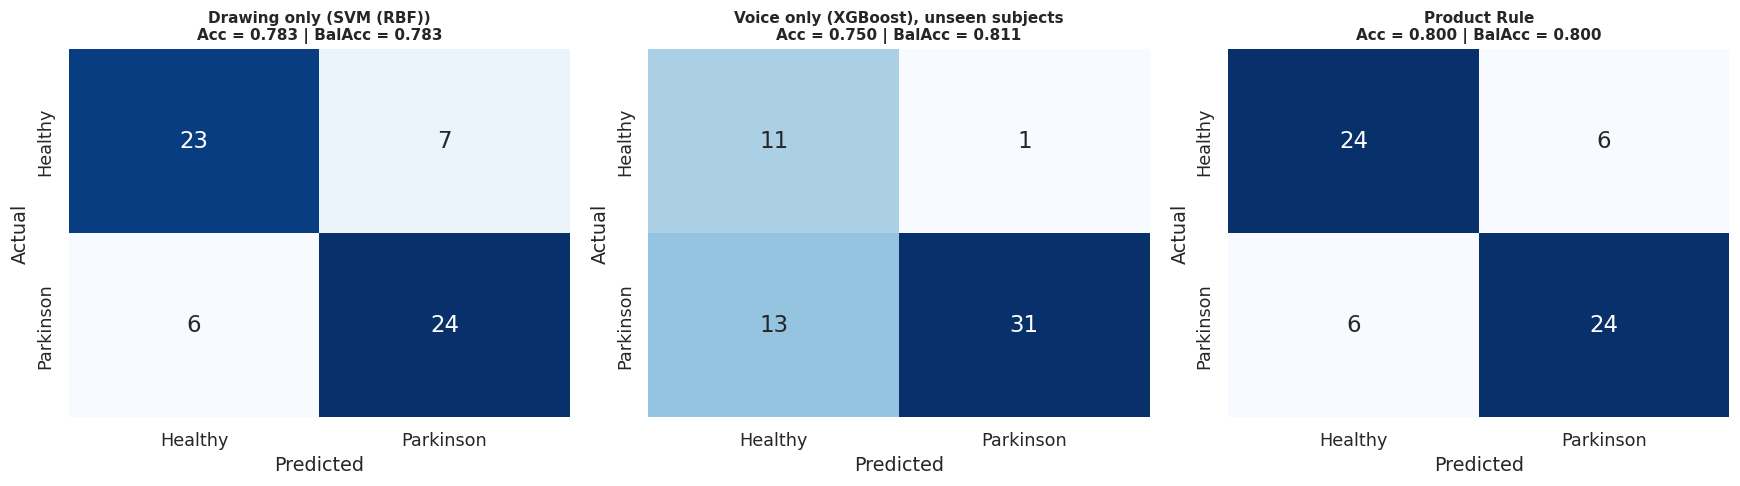

In [14]:
# ============================================================
# STEP 14 — Confusion matrices (repetition #0)
# ============================================================
s0 = store[0]
cms = [(f'Drawing only ({BEST_D})', yd_te, s0['probs']['Drawing only']),
       (f'Voice only ({BEST_V}), unseen subjects', s0['voice_test_y'], s0['voice_test_p']),
       (BEST_FUSION, yd_te, s0['probs'][BEST_FUSION])]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (t, y, p) in zip(axes, cms):
    pred = (p >= .5).astype(int)
    sns.heatmap(confusion_matrix(y, pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={'size': 15})
    ax.set_title(f'{t}\nAcc = {accuracy_score(y, pred):.3f} | BalAcc = {balanced_accuracy_score(y, pred):.3f}', fontweight='bold', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); savefig('fig06_confusion_matrices.png'); plt.show()

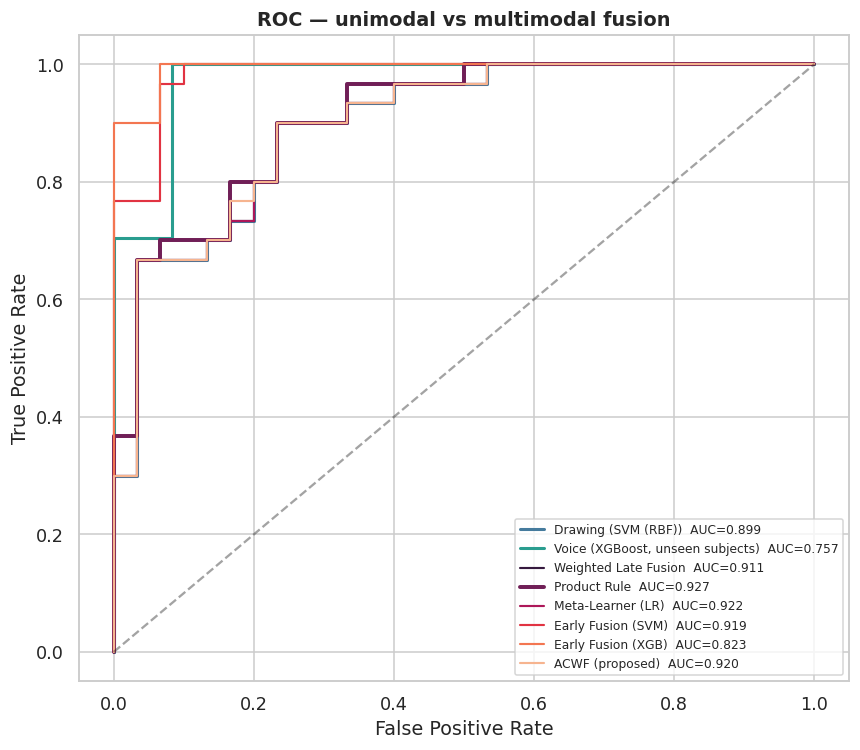

In [15]:
# ============================================================
# STEP 15 — ROC curves (repetition #0, legend shows mean AUC over all repetitions)
# ============================================================
mean_auc = {k: np.mean([m['AUC'] for m in log[k]]) for k in LOG_KEYS}
plt.figure(figsize=(8, 7))
fpr, tpr, _ = roc_curve(yd_te, s0['probs']['Drawing only'])
plt.plot(fpr, tpr, lw=2, color='#457b9d', label=f'Drawing ({BEST_D})  AUC={mean_auc["Drawing only"]:.3f}')
fpr, tpr, _ = roc_curve(s0['voice_test_y'], s0['voice_test_p'])
plt.plot(fpr, tpr, lw=2, color='#2a9d8f', label=f'Voice ({BEST_V}, unseen subjects)  AUC={mean_auc["Voice only (subject-wise test)"]:.3f}')
for s, c in zip(STRATS, sns.color_palette('rocket', len(STRATS))):
    fpr, tpr, _ = roc_curve(yd_te, s0['probs'][s])
    plt.plot(fpr, tpr, lw=2.6 if s == BEST_FUSION else 1.4, color=c, label=f'{s}  AUC={mean_auc[s]:.3f}')
plt.plot([0, 1], [0, 1], 'k--', alpha=.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC — unimodal vs multimodal fusion', fontweight='bold'); plt.legend(fontsize=8, loc='lower right')
plt.tight_layout(); savefig('fig07_roc_curves.png'); plt.show()

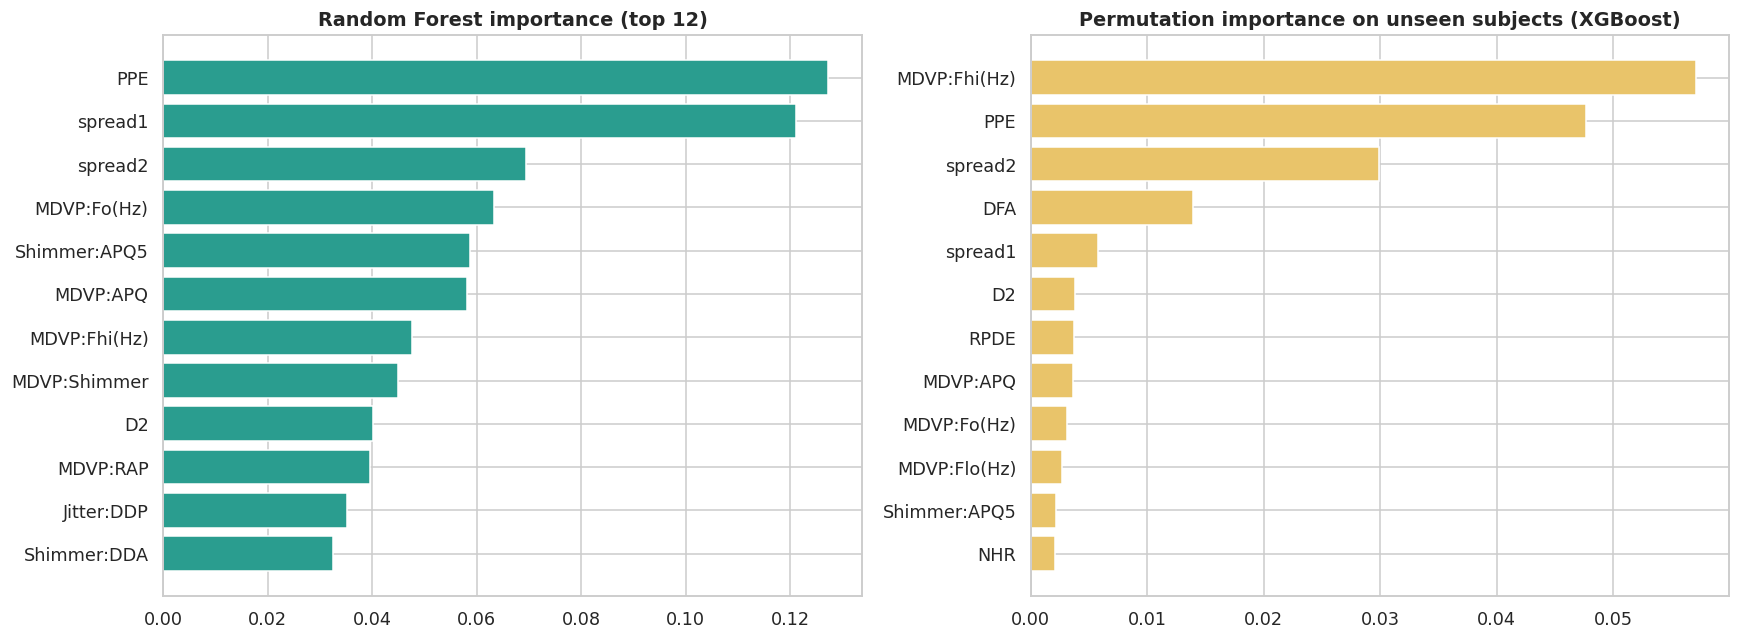

,Feature,RF_Gini,Permutation_AUC_drop
21,PPE,0.1273,0.0477
18,spread1,0.1212,0.0058
19,spread2,0.0695,0.0299
0,MDVP:Fo(Hz),0.0634,0.0031
11,Shimmer:APQ5,0.0586,0.0021
12,MDVP:APQ,0.0581,0.0036
1,MDVP:Fhi(Hz),0.0477,0.0571
8,MDVP:Shimmer,0.0449,0.0000
20,D2,0.0402,0.0038
5,MDVP:RAP,0.0395,0.0006


In [16]:
# ============================================================
# STEP 16 — Final deployable voice model + explainability
# ============================================================
fit_v_final = make_pipeline('voice', model_zoo(SPW_VOICE)[BEST_V]).fit(Xv_all, yv_all)
cal_v_final = PlattCalibrator().fit(voice_oof[BEST_V][0], yv_all)          # subject-wise OOF scores
REL_V_FINAL = max(roc_auc_score(yv_all, voice_oof[BEST_V][0]) - 0.5, 0.01)

rf_imp = RandomForestClassifier(n_estimators=500, class_weight='balanced', random_state=SEED).fit(StandardScaler().fit_transform(Xv_all), yv_all)
vtr0, vte0 = s0['vtr'], s0['vte']
pipe0 = make_pipeline('voice', model_zoo(SPW_VOICE)[BEST_V]).fit(Xv_all[vtr0], yv_all[vtr0])
pi = permutation_importance(pipe0, Xv_all[vte0], yv_all[vte0], n_repeats=30, random_state=SEED, scoring='roc_auc')
imp = pd.DataFrame({'Feature': VOICE_FEATURES, 'RF_Gini': rf_imp.feature_importances_,
                    'Permutation_AUC_drop': pi.importances_mean}).sort_values('RF_Gini', ascending=False)
imp.to_csv(os.path.join(OUT_DIR, 'voice_feature_importance.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top = imp.head(12)
axes[0].barh(top.Feature, top.RF_Gini, color='#2a9d8f'); axes[0].invert_yaxis()
axes[0].set_title('Random Forest importance (top 12)', fontweight='bold')
top2 = imp.sort_values('Permutation_AUC_drop', ascending=False).head(12)
axes[1].barh(top2.Feature, top2.Permutation_AUC_drop, color='#e9c46a'); axes[1].invert_yaxis()
axes[1].set_title(f'Permutation importance on unseen subjects ({BEST_V})', fontweight='bold')
plt.tight_layout(); savefig('fig08_voice_feature_importance.png'); plt.show()
display(imp.head(10).round(4))

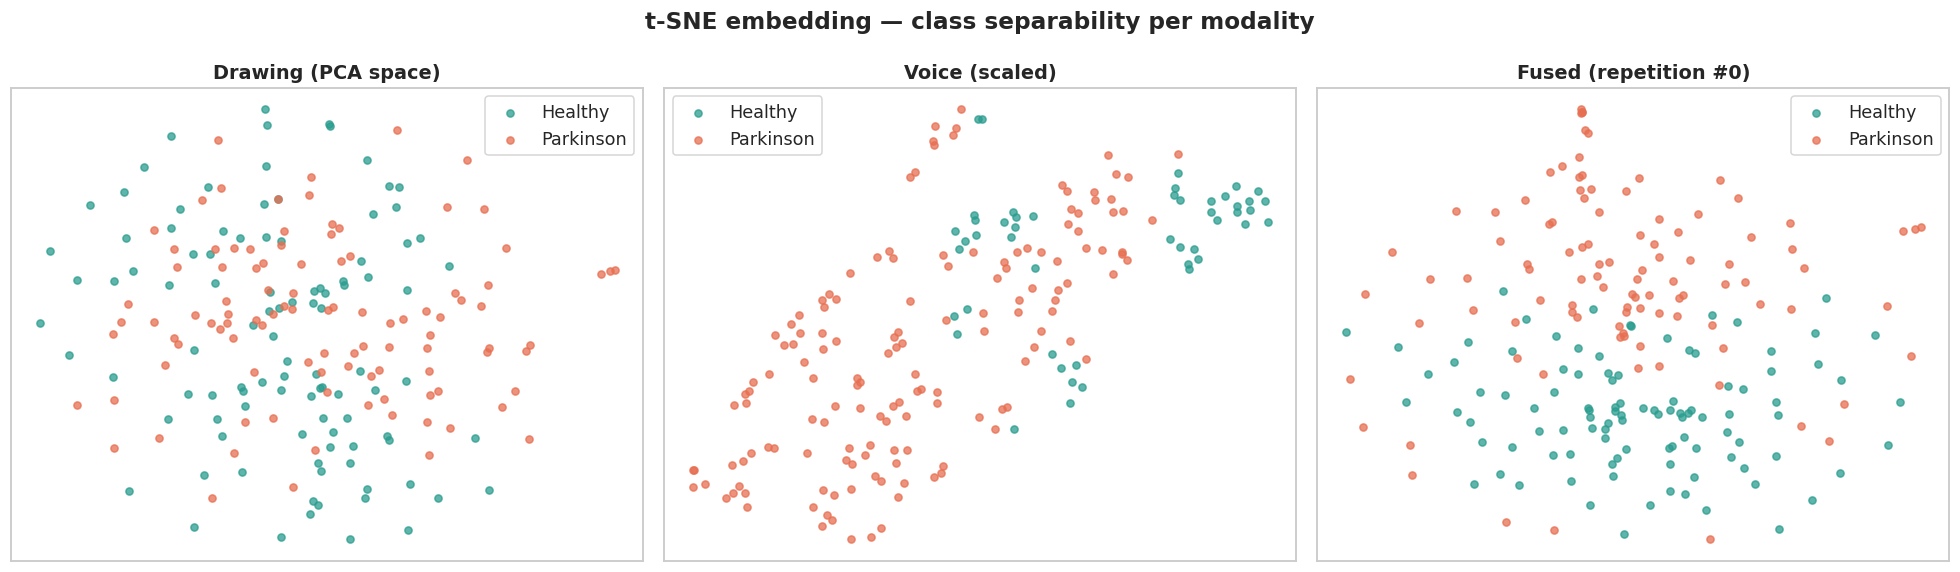

In [17]:
# ============================================================
# STEP 17 — t-SNE: drawing space, voice space, fused space
# ============================================================
vsc0 = StandardScaler().fit(Xv_all[vtr0])
fused = np.vstack([np.hstack([Zd_tr, vsc0.transform(Xv_all[vtr0])[s0['jtr']]]),
                   np.hstack([Zd_te, vsc0.transform(Xv_all[vte0])[s0['jte']]])])
spaces = [('Drawing (PCA space)', np.vstack([Zd_tr, Zd_te]), np.r_[yd_tr, yd_te]),
          ('Voice (scaled)', StandardScaler().fit_transform(Xv_all), yv_all),
          ('Fused (repetition #0)', fused, np.r_[yd_tr, yd_te])]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for ax, (t, X, y) in zip(axes, spaces):
    E = TSNE(n_components=2, perplexity=min(30, len(X) // 4), random_state=SEED, init='pca').fit_transform(StandardScaler().fit_transform(X))
    for c, col in [(0, '#2a9d8f'), (1, '#e76f51')]:
        ax.scatter(E[y == c, 0], E[y == c, 1], s=22, alpha=.75, c=col, label=CLASS_NAMES[c])
    ax.set_title(t, fontweight='bold'); ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('t-SNE embedding — class separability per modality', fontweight='bold')
plt.tight_layout(); savefig('fig09_tsne.png'); plt.show()

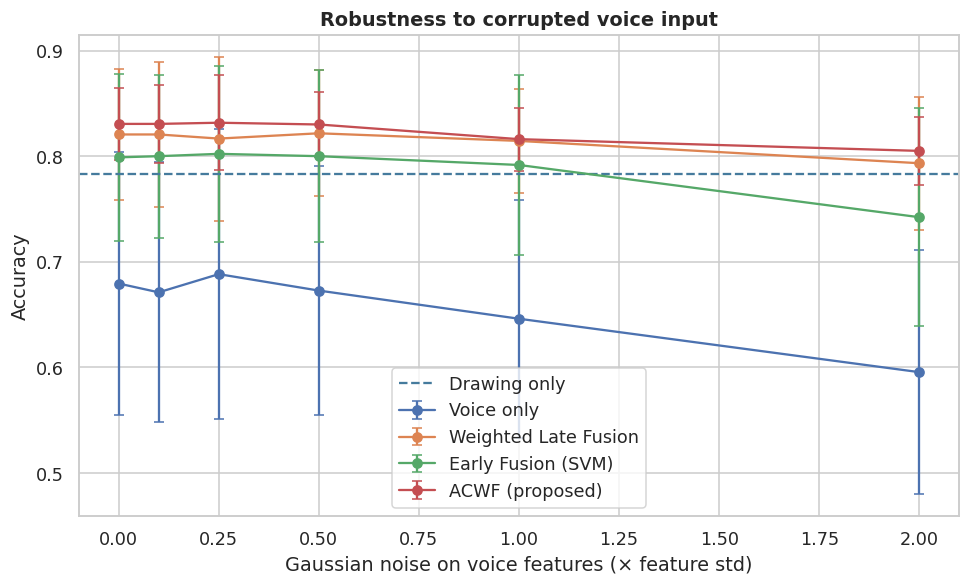

Method,ACWF (proposed),Early Fusion (SVM),Voice only,Weighted Late Fusion
Noise_sigma,,,,
0.00,0.8306,0.7989,0.6794,0.8206
0.10,0.8306,0.8000,0.6711,0.8206
0.25,0.8317,0.8022,0.6883,0.8167
0.50,0.8300,0.8000,0.6728,0.8217
1.00,0.8161,0.7917,0.6461,0.8144
2.00,0.8050,0.7422,0.5956,0.7933


,Scenario,Accuracy
0,Both modalities (Product Rule),0.8467
1,Both modalities (ACWF),0.8306
2,Voice missing → drawing only,0.7833
3,Drawing missing → voice only,0.6789


In [18]:
# ============================================================
# STEP 18 — Robustness: noisy voice + missing modality
# ============================================================
rob_df = pd.DataFrame(rob).groupby(['Noise_sigma', 'Method'], sort=False).Accuracy.agg(['mean', 'std']).reset_index()
rob_df.to_csv(os.path.join(OUT_DIR, 'robustness_noise.csv'), index=False)

plt.figure(figsize=(9, 5.5))
for name, g in rob_df.groupby('Method', sort=False):
    plt.errorbar(g.Noise_sigma, g['mean'], yerr=g['std'], marker='o', capsize=3, label=name)
plt.axhline(log['Drawing only'][0]['Accuracy'], ls='--', color='#457b9d', label='Drawing only')
plt.xlabel('Gaussian noise on voice features (× feature std)'); plt.ylabel('Accuracy')
plt.title('Robustness to corrupted voice input', fontweight='bold'); plt.legend()
plt.tight_layout(); savefig('fig10_robustness_noise.png'); plt.show()

acc = lambda k: np.mean([m['Accuracy'] for m in log[k]])
missing = pd.DataFrame([
    dict(Scenario=f'Both modalities ({BEST_FUSION})', Accuracy=acc(BEST_FUSION)),
    dict(Scenario='Both modalities (ACWF)', Accuracy=acc('ACWF (proposed)')),
    dict(Scenario='Voice missing → drawing only', Accuracy=acc('Drawing only')),
    dict(Scenario='Drawing missing → voice only', Accuracy=acc('Voice only (paired rows)')),
])
missing.to_csv(os.path.join(OUT_DIR, 'robustness_missing_modality.csv'), index=False)
display(rob_df.pivot(index='Noise_sigma', columns='Method', values='mean').round(4))
display(missing.round(4))

In [19]:
# ============================================================
# STEP 19 — Statistical significance (paired over 30 repetitions)
# ============================================================
def wilcoxon_greater(x, y):
    d = np.asarray(x) - np.asarray(y)
    if not np.any(d != 0): return 1.0
    try: return stats.wilcoxon(d, alternative='greater').pvalue
    except ValueError: return 1.0

d_acc = np.array([m['Accuracy'] for m in log['Drawing only']])
v_acc = np.array([m['Accuracy'] for m in log['Voice only (paired rows)']])
sig = []
for s in STRATS:
    a = np.array([m['Accuracy'] for m in log[s]])
    ci = stats.t.interval(0.95, len(a) - 1, loc=a.mean(), scale=stats.sem(a)) if a.std() > 0 else (a.mean(), a.mean())
    sig.append(dict(Strategy=s, Mean_Acc=a.mean(), CI95_low=ci[0], CI95_high=ci[1],
                    Gain_vs_Drawing=(a - d_acc).mean(), p_vs_Drawing=wilcoxon_greater(a, d_acc),
                    Gain_vs_Voice=(a - v_acc).mean(), p_vs_Voice=wilcoxon_greater(a, v_acc)))
sig = pd.DataFrame(sig)
sig['Better_than_both'] = (sig.p_vs_Drawing < 0.05) & (sig.p_vs_Voice < 0.05)
sig.to_csv(os.path.join(OUT_DIR, 'statistical_tests.csv'), index=False)
display(sig.round(4))

,Strategy,Mean_Acc,CI95_low,CI95_high,Gain_vs_Drawing,p_vs_Drawing,Gain_vs_Voice,p_vs_Voice,Better_than_both
0,Weighted Late Fusion,0.8211,0.7980,0.8442,0.0378,0.0004,0.1422,0.0000,True
1,Product Rule,0.8467,0.8307,0.8626,0.0633,0.0000,0.1678,0.0000,True
2,Meta-Learner (LR),0.8383,0.8215,0.8552,0.0550,0.0000,0.1594,0.0000,True
3,Early Fusion (SVM),0.7989,0.7693,0.8284,0.0156,0.1444,0.1200,0.0001,False
4,Early Fusion (XGB),0.7106,0.6520,0.7691,-0.0728,0.9839,0.0317,0.0119,False
5,ACWF (proposed),0.8306,0.8178,0.8433,0.0472,0.0000,0.1517,0.0000,True


In [20]:
# ============================================================
# STEP 20 — Inference function (drawing image + optional voice) — uses ACWF
# ============================================================
# ACWF is used for deployment because it (a) needs no paired training data,
# (b) works when one modality is missing, and (c) adds almost no compute on a phone/server.
def predict_multimodal(image_path=None, voice_features=None):
    out, pd_, pv_ = {}, None, None
    if image_path is not None:
        cnn = cnn_features([image_path], cnn_extractor)
        x = np.hstack([cnn, handcrafted_features(image_path)[None]]) if DRAW_FEATURE_SET == 'hybrid' else cnn
        pd_ = float(cal_d.transform(fit_d[BEST_D].predict_proba(x)[:, 1])[0]); out['p_parkinson_drawing'] = round(pd_ * 100, 2)
    if voice_features is not None:
        v = np.array([voice_features[f] for f in VOICE_FEATURES] if isinstance(voice_features, dict) else voice_features,
                     dtype=np.float32)[None]
        pv_ = float(cal_v_final.transform(fit_v_final.predict_proba(v)[:, 1])[0]); out['p_parkinson_voice'] = round(pv_ * 100, 2)
    if pd_ is not None and pv_ is not None:
        p = float(acwf(np.array([pd_]), np.array([pv_]), REL_D, REL_V_FINAL, GAMMA_FINAL)[0]); out['mode'] = 'multimodal (ACWF)'
    elif pd_ is not None:
        p = pd_; out['mode'] = 'drawing only'
    elif pv_ is not None:
        p = pv_; out['mode'] = 'voice only'
    else:
        raise ValueError('Give at least one modality')
    out.update(prediction=CLASS_NAMES[int(p >= .5)], p_parkinson=round(p * 100, 2), p_healthy=round((1 - p) * 100, 2))
    return out

te_rows = draw_df[~tr_mask].reset_index(drop=True)
for c in (0, 1):
    i = int(np.where(te_rows.label == c)[0][0]); j = int(np.where(yv_all[vte0] == c)[0][0])
    print(f'True = {CLASS_NAMES[c]:9s} →', predict_multimodal(te_rows.path[i], dict(zip(VOICE_FEATURES, Xv_all[vte0][j]))))

True = Healthy   → {'p_parkinson_drawing': 29.52, 'p_parkinson_voice': 4.16, 'mode': 'multimodal (ACWF)', 'prediction': 'Healthy', 'p_parkinson': 13.86, 'p_healthy': 86.14}
True = Parkinson → {'p_parkinson_drawing': 43.08, 'p_parkinson_voice': 82.07, 'mode': 'multimodal (ACWF)', 'prediction': 'Parkinson', 'p_parkinson': 61.79, 'p_healthy': 38.21}


In [21]:
# ============================================================
# STEP 21 — Save all artifacts & download
# ============================================================
joblib.dump(fit_d[BEST_D], os.path.join(MODEL_DIR, 'MM_drawing_pipeline.pkl'))
joblib.dump(cal_d,         os.path.join(MODEL_DIR, 'MM_drawing_calibrator.pkl'))
joblib.dump(fit_v_final,   os.path.join(MODEL_DIR, 'MM_voice_pipeline.pkl'))
joblib.dump(cal_v_final,   os.path.join(MODEL_DIR, 'MM_voice_calibrator.pkl'))
cnn_extractor.save(os.path.join(MODEL_DIR, 'mobilenet_extractor.keras'))

import sklearn
config = dict(
    drawing_model=BEST_D, voice_model=BEST_V, draw_feature_set=DRAW_FEATURE_SET,
    hog=dict(size=128, orientations=9, pixels_per_cell=8, cells_per_block=2),
    lbp=dict(P=24, R=3, bins=26), voice_features=VOICE_FEATURES,
    fusion=dict(best_strategy=BEST_FUSION, deployed_strategy='ACWF', acwf_gamma=GAMMA_FINAL,
                reliability_drawing=round(REL_D, 4), reliability_voice=round(REL_V_FINAL, 4),
                weighted_late_w_drawing_median=W_FINAL),
    protocol=dict(voice='subject-wise (StratifiedGroupKFold / held-out subjects)', voice_test_fraction=VOICE_TEST_FRAC,
                  repetitions=N_PAIRINGS, voice_cv_repeats=N_VOICE_REPEATS),
    versions=dict(sklearn=sklearn.__version__, tensorflow=tf.__version__, numpy=np.__version__),
    results={r.Approach: dict(accuracy=round(r.Accuracy_mean, 4), accuracy_std=round(r.Accuracy_std, 4),
                              bal_acc=round(r.BalAcc_mean, 4), auc=round(r.AUC_mean, 4), f1=round(r.F1_mean, 4))
             for r in final_df.itertuples()},
)
with open(os.path.join(MODEL_DIR, 'MM_config.json'), 'w') as f:
    json.dump(config, f, indent=2)

zip_base = os.path.join(BASE_DIR, 'multimodal_PD_results')
shutil.make_archive(zip_base, 'zip', OUT_DIR)
print('📦 Saved:', zip_base + '.zip')
for root, _, fs in os.walk(OUT_DIR):
    for f in sorted(fs):
        print('   ', os.path.relpath(os.path.join(root, f), OUT_DIR))
if IN_COLAB:
    colab_files.download(zip_base + '.zip')

📦 Saved: /content/multimodal_PD_results.zip
    multimodal_results_raw.csv
    multimodal_results_table.csv
    robustness_missing_modality.csv
    robustness_noise.csv
    statistical_tests.csv
    unimodal_all_models.csv
    voice_feature_importance.csv
    figures/fig01_voice_distributions.png
    figures/fig02_voice_correlation.png
    figures/fig03_unimodal_comparison.png
    figures/fig04_unimodal_vs_multimodal.png
    figures/fig05_fusion_sensitivity_stability.png
    figures/fig06_confusion_matrices.png
    figures/fig07_roc_curves.png
    figures/fig08_voice_feature_importance.png
    figures/fig09_tsne.png
    figures/fig10_robustness_noise.png
    models/MM_config.json
    models/MM_drawing_calibrator.pkl
    models/MM_drawing_pipeline.pkl
    models/MM_voice_calibrator.pkl
    models/MM_voice_pipeline.pkl
    models/mobilenet_extractor.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# ============================================================
# STEP 22 — Paper-ready summary
# ============================================================
print('=' * 80)
print('  MULTIMODAL PD DETECTION — SUMMARY FOR BOOK CHAPTER 14')
print('=' * 80)
print(f'Drawing : {len(draw_df)} images | {F_draw.shape[1]} features → PCA {fit_d[BEST_D].named_steps["pca"].n_components_} | best = {BEST_D}')
print(f'Voice   : {len(voice_df)} recordings / {voice_df.subject.nunique()} subject IDs | 22 features | best = {BEST_V}')
print(f'Fusion  : {N_PAIRINGS} repetitions (new voice-subject split + new pairing each) | ACWF gamma = {GAMMA_FINAL}')
print('-' * 80)
for r in final_df.itertuples():
    print(f'{r.Approach:48s} Acc {r.Accuracy_mean*100:6.2f} ± {r.Accuracy_std*100:5.2f}%  BalAcc {r.BalAcc_mean*100:6.2f}%  AUC {r.AUC_mean:.3f}')
print('-' * 80)
print('🏆 Best multimodal strategy:', BEST_FUSION)
print('Better than BOTH unimodal baselines (p<0.05):', ', '.join(sig.loc[sig.Better_than_both, 'Strategy']) or 'none')

  MULTIMODAL PD DETECTION — SUMMARY FOR BOOK CHAPTER 14
Drawing : 204 images | 9406 features → PCA 122 | best = SVM (RBF)
Voice   : 195 recordings / 32 subject IDs | 22 features | best = XGBoost
Fusion  : 30 repetitions (new voice-subject split + new pairing each) | ACWF gamma = 0.0
--------------------------------------------------------------------------------
Drawing only — SVM (RBF)                         Acc  78.33 ±  0.00%  BalAcc  78.33%  AUC 0.899
Voice only — XGBoost (unseen subjects)           Acc  70.07 ± 10.34%  BalAcc  67.35%  AUC 0.757
Voice only — XGBoost (paired rows)               Acc  67.89 ± 12.43%  BalAcc  67.89%  AUC 0.757
Weighted Late Fusion                             Acc  82.11 ±  6.19%  BalAcc  82.11%  AUC 0.911
Product Rule                                     Acc  84.67 ±  4.28%  BalAcc  84.67%  AUC 0.927
Meta-Learner (LR)                                Acc  83.83 ±  4.51%  BalAcc  83.83%  AUC 0.922
Early Fusion (SVM)                               Acc  79.89

## 📝 Paper-এর জন্য নোট

**Results section-এ যা যা দেবেন**
- Table 1: `unimodal_all_models.csv` — 7 classifier × 2 modality (drawing: official split, voice: subject-wise CV × 5)
- Table 2: `multimodal_results_table.csv` — unimodal vs 6 fusion strategy (mean ± std, 30 repetitions)
- Table 3: `statistical_tests.csv` — দুটো unimodal-এর বিরুদ্ধেই Wilcoxon p-value ও 95% CI
- Figure 3–10: `figures/` ফোল্ডার (300 dpi)

**Evaluation protocol (Methods-এ লিখবেন)**
1. Voice: সব জায়গায় subject-wise — একই মানুষের recording কখনো train আর test দুই জায়গায় নেই।
2. Class imbalance (75% PD) → class-balanced classifier + out-of-fold Platt calibration; তাই Balanced Accuracy-ও report করা হয়েছে।
3. প্রতিটি repetition-এ নতুন voice-subject split + নতুন class-matched pairing → mean ± std-এ দুই ধরনের variation-ই আছে।
4. Fusion-এর সব parameter (w, γ, meta-learner, early-fusion model) শুধু train pair থেকে শেখা।
5. দুটো modality থাকলে Product Rule আর 0.5/0.5 average-এর decision গাণিতিকভাবে একই (p_d + p_v > 1) — তাই accuracy এক, শুধু AUC আলাদা।

**Limitation (অবশ্যই লিখবেন)**
- Drawing ও voice ভিন্ন cohort থেকে → pseudo-paired *simulated multimodal cohort*; real paired cohort-এ validation দরকার।
- Voice dataset ছোট (≈31 জন, ৮ জন healthy) — তাই variance বেশি।
- Future work: mPower (Synapse) বা নিজস্ব paired data, raw audio থেকে Praat/parselmouth দিয়ে feature extraction, app-এ voice recording যোগ করা।